# Concept Drift Experiment for Lightweight IoT IDS

This notebook is modified to **read data directly from the existing project sources** created by the earlier preprocessing pipeline.

It supports two input modes:

1. Preferred: `data/processed/X_train_scaled.csv`, `X_test_scaled.csv`, `y_train_binary.csv`, `y_test_binary.csv`
2. Fallback: `data/processed/final_sample_200000.csv`

The experiment uses the established **Top-15 lightweight feature set** and simulates a streaming IDS setting with drift detection.

## Important correction note

This version has been cleaned to avoid the earlier errors:

- The duplicate full-stream monitoring cell was removed.
- The cell that overwrote `comparison` with only one row was removed.
- Static RF and Adaptive Online SGD now both use the same `X_stream_small` and `y_stream_small`.
- Therefore, `y_eval`, `preds`, and `online_preds` should have the same length.

In [1]:
# ============================================================
# 1. Project setup and source discovery
# ============================================================

from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore")

# If you run the notebook from G:\IoT_IDS_Research, this will work automatically.
# If not, change PROJECT_DIR manually below.
#PROJECT_DIR = Path.cwd()


# Optional: uncomment and edit this line if your notebook is not inside the project folder.
PROJECT_DIR = Path(r"G:\IoT_IDS_Research")

DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "concept_drift"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project directory: G:\IoT_IDS_Research
Processed data directory: G:\IoT_IDS_Research\data\processed
Output directory: G:\IoT_IDS_Research\outputs\concept_drift
Data directory exists: True


In [2]:
# ============================================================
# 2. Imports
# ============================================================

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
DATA_DIR

WindowsPath('G:/IoT_IDS_Research/data/processed')

In [4]:
# ============================================================
# 3. Load IDS data from existing preprocessing outputs
# ============================================================

X_train_path = DATA_DIR / "X_train_scaled.csv"
X_test_path = DATA_DIR / "X_test_scaled.csv"
y_train_path = DATA_DIR / "y_train_binary.csv"
y_test_path = DATA_DIR / "y_test_binary.csv"
final_sample_path = DATA_DIR / "final_sample_200000.csv"

required_split_files = [X_train_path, X_test_path, y_train_path, y_test_path]

if all(p.exists() for p in required_split_files):
    print("Loading scaled train-test files from data/processed...")
    X_train = pd.read_csv(X_train_path)
    X_test = pd.read_csv(X_test_path)
    y_train = pd.read_csv(y_train_path).values.ravel()
    y_test = pd.read_csv(y_test_path).values.ravel()
    source_mode = "scaled_train_test_files"

elif final_sample_path.exists():
    print("Scaled train-test files not found. Loading final_sample_200000.csv instead...")
    from sklearn.model_selection import train_test_split

    df = pd.read_csv(final_sample_path)
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]

    if "Binary_Label" not in df.columns:
        raise ValueError("Binary_Label column is missing in final_sample_200000.csv")

    drop_cols = [c for c in ["Label", "Binary_Label", "Attack_Category"] if c in df.columns]
    X = df.drop(columns=drop_cols)
    X = X.select_dtypes(include=[np.number]).copy()
    y = df["Binary_Label"].astype(int).values

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    scaler = StandardScaler()
    X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns)
    X_test = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns)
    joblib.dump(scaler, OUTPUT_DIR / "concept_drift_scaler.joblib")
    source_mode = "final_sample_200000"

else:
    raise FileNotFoundError(
        "No valid input source found. Expected either scaled train-test files or final_sample_200000.csv in data/processed."
    )

print("Source mode:", source_mode)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("Train label distribution:")
print(pd.Series(y_train).value_counts().sort_index())
print("Test label distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Loading scaled train-test files from data/processed...
Source mode: scaled_train_test_files
X_train: (160000, 39)
X_test : (40000, 39)
y_train: (160000,)
y_test : (40000,)
Train label distribution:
0    80000
1    80000
Name: count, dtype: int64
Test label distribution:
0    20000
1    20000
Name: count, dtype: int64


In [5]:
# ============================================================
# 4. Select the established Top-15 lightweight features
# ============================================================

top_15_features = [
    "Number",
    "ack_flag_number",
    "HTTPS",
    "Tot_size",
    "Rate",
    "Header_Length",
    "IAT",
    "AVG",
    "ack_count",
    "Variance",
    "Std",
    "Max",
    "Tot_sum",
    "Time_To_Live",
    "Min"
]

missing = [f for f in top_15_features if f not in X_train.columns]
if missing:
    print("WARNING: Missing Top-15 features:", missing)
    print("Available columns:", list(X_train.columns))
    raise ValueError("Some Top-15 features are missing. Check column names.")

X_train_15 = X_train[top_15_features].copy()
X_test_15 = X_test[top_15_features].copy()

print("Top-15 train shape:", X_train_15.shape)
print("Top-15 test shape :", X_test_15.shape)

Top-15 train shape: (160000, 15)
Top-15 test shape : (40000, 15)


In [6]:
# ============================================================
# 5. Static baseline: RF Top-15 before drift simulation
# ============================================================

start = time.time()
rf_static = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_static.fit(X_train_15, y_train)
train_time = time.time() - start

start = time.time()
y_pred_static = rf_static.predict(X_test_15)
infer_time = time.time() - start

print("Static RF Top-15 Baseline")
print("Training time:", train_time)
print("Inference time:", infer_time)
print("Accuracy:", accuracy_score(y_test, y_pred_static))
print("F1:", f1_score(y_test, y_pred_static))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_static))
print("MCC:", matthews_corrcoef(y_test, y_pred_static))
print(classification_report(y_test, y_pred_static))
print(confusion_matrix(y_test, y_pred_static))

joblib.dump(rf_static, OUTPUT_DIR / "rf_static_top15.joblib")

Static RF Top-15 Baseline
Training time: 12.848560810089111
Inference time: 0.2055199146270752
Accuracy: 0.988575
F1: 0.9884540562391047
Balanced Accuracy: 0.988575
MCC: 0.977364507402397
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19981    19]
 [  438 19562]]


['G:\\IoT_IDS_Research\\outputs\\concept_drift\\rf_static_top15.joblib']

## Concept drift design

For this first drift experiment, we create a stream from the test data and intentionally introduce distribution shift. This is not a replacement for real timestamp-based drift, but it is a valid first controlled experiment for checking whether the IDS can detect performance degradation under changing traffic patterns.

The drift detector observes the **prediction error stream**: `0 = correct`, `1 = wrong`. When the error distribution changes, drift is flagged.

In [7]:
# ============================================================
# 6. Build a controlled IoT stream with simulated concept drift
# ============================================================

X_stream_base = X_test_15.copy().reset_index(drop=True)
y_stream_base = pd.Series(y_test).reset_index(drop=True)

# Phase 1: original test data
X_phase1 = X_stream_base.copy()
y_phase1 = y_stream_base.copy()

# Phase 2: covariate drift / traffic-behavior shift
X_phase2 = X_stream_base.copy()
y_phase2 = y_stream_base.copy()
shift_features = ["Rate", "IAT", "Tot_size", "Header_Length", "Variance"]
for col in shift_features:
    if col in X_phase2.columns:
        X_phase2[col] = X_phase2[col] * 1.35 + 0.25

# Phase 3: stronger stress drift by changing important control/statistical features
X_phase3 = X_stream_base.copy()
y_phase3 = y_stream_base.copy()
strong_shift_features = ["Number", "Time_To_Live", "AVG", "Std", "Max", "Tot_sum"]
for col in strong_shift_features:
    if col in X_phase3.columns:
        X_phase3[col] = X_phase3[col] * 0.65 - 0.15

X_stream = pd.concat([X_phase1, X_phase2, X_phase3], ignore_index=True)
y_stream = pd.concat([y_phase1, y_phase2, y_phase3], ignore_index=True).astype(int).values

phase_boundaries = [len(X_phase1), len(X_phase1) + len(X_phase2), len(X_stream)]
print("Stream shape:", X_stream.shape)
print("Phase boundaries:", phase_boundaries)
print("Stream label distribution:")
print(pd.Series(y_stream).value_counts().sort_index())

Stream shape: (120000, 15)
Phase boundaries: [40000, 80000, 120000]
Stream label distribution:
0    60000
1    60000
Name: count, dtype: int64


In [8]:
# ============================================================
# 7. Drift detector setup: River ADWIN if available, fallback detector otherwise
# ============================================================

try:
    from river import drift
    river_available = True
    adwin = drift.ADWIN(delta=0.002)
    print("Using River ADWIN drift detector.")
except Exception as e:
    river_available = False
    adwin = None
    print("River is not available. Using fallback sliding-window drift detector.")
    print("Reason:", repr(e))

class FallbackWindowDriftDetector:
    # Simple fallback detector based on difference between two error windows.
    def __init__(self, window_size=500, threshold=0.12):
        self.window_size = window_size
        self.threshold = threshold
        self.errors = []
        self.drift_detected = False

    def update(self, error):
        self.errors.append(int(error))
        self.drift_detected = False
        if len(self.errors) >= 2 * self.window_size:
            old = self.errors[-2*self.window_size:-self.window_size]
            new = self.errors[-self.window_size:]
            if abs(np.mean(new) - np.mean(old)) > self.threshold:
                self.drift_detected = True
        return self

fallback_detector = FallbackWindowDriftDetector(window_size=500, threshold=0.08)

Using River ADWIN drift detector.


In [20]:
# ============================================================
# 8. Static RF stream monitoring with drift detection - FAST VERSION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

# Use smaller stream first for testing
MAX_STREAM_SAMPLES = 120000

X_stream_small = X_stream.iloc[:MAX_STREAM_SAMPLES].copy() if hasattr(X_stream, "iloc") else pd.DataFrame(X_stream[:MAX_STREAM_SAMPLES], columns=top_15_features)
y_stream_small = y_stream.iloc[:MAX_STREAM_SAMPLES].copy() if hasattr(y_stream, "iloc") else y_stream[:MAX_STREAM_SAMPLES]

print("Using stream samples:", len(y_stream_small))

errors = []
drift_points = []

# Predict full stream at once
X_stream_df = pd.DataFrame(X_stream_small, columns=top_15_features)

start_time = time.time()
preds = rf_static.predict(X_stream_df).astype(int)
prediction_time = time.time() - start_time

print("Prediction completed in seconds:", prediction_time)

# Feed errors one by one to ADWIN
for i, (y_true, y_pred) in enumerate(zip(y_stream_small, preds)):
    error = int(y_pred != y_true)
    errors.append(error)

    if river_available:
        adwin.update(error)

        if hasattr(adwin, "drift_detected"):
            drift_now = adwin.drift_detected
        elif hasattr(adwin, "change_detected"):
            drift_now = adwin.change_detected
        else:
            drift_now = False
    else:
        fallback_detector.update(error)
        drift_now = fallback_detector.drift_detected

    if drift_now:
        drift_points.append(i)

print("Total stream samples:", len(y_stream_small))
print("Total drift points detected:", len(drift_points))
print("First 20 drift points:", drift_points[:20])

stream_accuracy = accuracy_score(y_stream_small, preds)
stream_f1 = f1_score(y_stream_small, preds)

print("Static RF stream accuracy:", stream_accuracy)
print("Static RF stream F1:", stream_f1)
print("Confusion matrix:")
print(confusion_matrix(y_stream_small, preds))

Using stream samples: 120000
Prediction completed in seconds: 0.32742929458618164
Total stream samples: 120000
Total drift points detected: 2
First 20 drift points: [2655, 81215]
Static RF stream accuracy: 0.9824416666666667
Static RF stream F1: 0.9823739532704807
Confusion matrix:
[[59177   823]
 [ 1284 58716]]


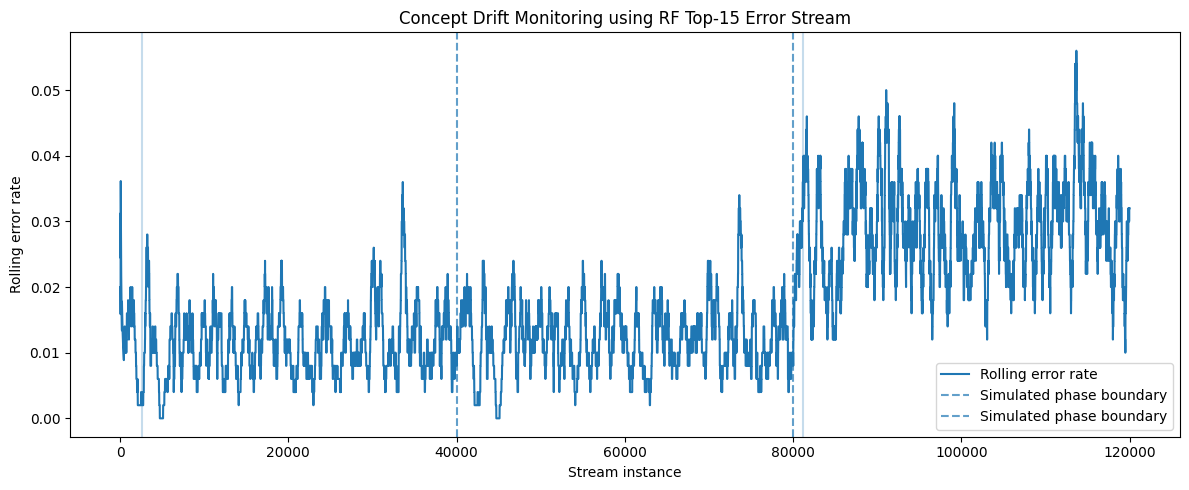

In [21]:
# ============================================================
# 9. Plot stream error rate and detected drift points
# ============================================================

error_series = pd.Series(errors)
rolling_error = error_series.rolling(window=500, min_periods=50).mean()

plt.figure(figsize=(12, 5))
plt.plot(rolling_error.values, label="Rolling error rate")

for boundary in phase_boundaries[:-1]:
    plt.axvline(boundary, linestyle="--", alpha=0.7, label="Simulated phase boundary")

for dp in drift_points[:20]:
    plt.axvline(dp, alpha=0.25)

plt.xlabel("Stream instance")
plt.ylabel("Rolling error rate")
plt.title("Concept Drift Monitoring using RF Top-15 Error Stream")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_top15_drift_monitoring.png", dpi=300)
plt.show()

## Adaptive online IDS model

Random Forest is strong for static IDS, but it is not naturally incremental. For concept-drift-aware IDS, we also test an online learner using `SGDClassifier.partial_fit`. This gives a practical first adaptive baseline.

In [22]:
# ============================================================
# 10. Online adaptive IDS using SGDClassifier.partial_fit - FAST VERSION
# ============================================================

# IMPORTANT:
# This cell uses the same reduced stream used by the static RF cell:
# X_stream_small and y_stream_small.
# This keeps all arrays equal in length and prevents very long execution.

online_model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=0.0001,
    random_state=RANDOM_STATE
)

classes = np.array([0, 1])
online_model.partial_fit(X_train_15.values, y_train, classes=classes)

online_preds = []
online_errors = []
online_drift_points = []

if river_available:
    online_detector = drift.ADWIN(delta=0.002)
else:
    online_detector = FallbackWindowDriftDetector(window_size=500, threshold=0.08)

# Use small stream for fast execution
X_online_stream = X_stream_small.copy()
y_online_stream = np.array(y_stream_small)

start_time = time.time()

for i, (x_row, y_true) in enumerate(zip(X_online_stream.values, y_online_stream)):
    x_2d = x_row.reshape(1, -1)
    y_pred = int(online_model.predict(x_2d)[0])
    online_preds.append(y_pred)

    error = int(y_pred != y_true)
    online_errors.append(error)

    if river_available:
        online_detector.update(error)

        if hasattr(online_detector, "drift_detected"):
            drift_now = online_detector.drift_detected
        elif hasattr(online_detector, "change_detected"):
            drift_now = online_detector.change_detected
        else:
            drift_now = False
    else:
        online_detector.update(error)
        drift_now = online_detector.drift_detected

    if drift_now:
        online_drift_points.append(i)

    # Adaptive update after observing true label
    online_model.partial_fit(x_2d, np.array([y_true]), classes=classes)

online_time = time.time() - start_time

print("Online adaptive IDS results")
print("Stream samples used:", len(y_online_stream))
print("Execution time in seconds:", online_time)
print("Accuracy:", accuracy_score(y_online_stream, online_preds))
print("F1:", f1_score(y_online_stream, online_preds, zero_division=0))
print("Balanced Accuracy:", balanced_accuracy_score(y_online_stream, online_preds))
print("MCC:", matthews_corrcoef(y_online_stream, online_preds))
print("Detected drift points:", online_drift_points[:20])
print(classification_report(y_online_stream, online_preds, zero_division=0))
print(confusion_matrix(y_online_stream, online_preds))

joblib.dump(online_model, OUTPUT_DIR / "online_sgd_top15.joblib")

Online adaptive IDS results
Stream samples used: 120000
Execution time in seconds: 230.29819560050964
Accuracy: 0.9815166666666667
F1: 0.9811928705886344
Balanced Accuracy: 0.9815166666666667
MCC: 0.9636047538899681
Detected drift points: []
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     60000
           1       1.00      0.96      0.98     60000

    accuracy                           0.98    120000
   macro avg       0.98      0.98      0.98    120000
weighted avg       0.98      0.98      0.98    120000

[[59924    76]
 [ 2142 57858]]


['G:\\IoT_IDS_Research\\outputs\\concept_drift\\online_sgd_top15.joblib']

In [23]:
# ============================================================
# 11. Compare static RF and adaptive online IDS on stream - final corrected version
# ============================================================

# Use exactly the same stream portion for both models.
y_eval = np.array(y_stream_small)

# Make sure all arrays have the same length.
min_len = min(len(y_eval), len(preds), len(online_preds))

y_eval_final = y_eval[:min_len]
preds_final = np.array(preds)[:min_len]
online_preds_final = np.array(online_preds)[:min_len]

print("Evaluation samples:", min_len)
print("y_eval length:", len(y_eval_final))
print("Static RF predictions length:", len(preds_final))
print("Adaptive online predictions length:", len(online_preds_final))

comparison = pd.DataFrame([
    {
        "Model": "Static RF Top-15",
        "Accuracy": accuracy_score(y_eval_final, preds_final),
        "Precision": precision_score(y_eval_final, preds_final, zero_division=0),
        "Recall": recall_score(y_eval_final, preds_final, zero_division=0),
        "F1": f1_score(y_eval_final, preds_final, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_eval_final, preds_final),
        "MCC": matthews_corrcoef(y_eval_final, preds_final),
        "Drift Points Detected": len(drift_points)
    },
    {
        "Model": "Adaptive Online SGD Top-15",
        "Accuracy": accuracy_score(y_eval_final, online_preds_final),
        "Precision": precision_score(y_eval_final, online_preds_final, zero_division=0),
        "Recall": recall_score(y_eval_final, online_preds_final, zero_division=0),
        "F1": f1_score(y_eval_final, online_preds_final, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_eval_final, online_preds_final),
        "MCC": matthews_corrcoef(y_eval_final, online_preds_final),
        "Drift Points Detected": len(online_drift_points)
    }
])

comparison.to_csv(OUTPUT_DIR / "concept_drift_model_comparison.csv", index=False)
comparison

Evaluation samples: 120000
y_eval length: 120000
Static RF predictions length: 120000
Adaptive online predictions length: 120000


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected
0,Static RF Top-15,0.982442,0.986177,0.9786,0.982374,0.982442,0.964912,2
1,Adaptive Online SGD Top-15,0.981517,0.998688,0.9643,0.981193,0.981517,0.963605,0


In [24]:
# ============================================================
# 12. Save experiment summary - corrected safe version
# ============================================================

summary_path = OUTPUT_DIR / "concept_drift_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("Concept Drift IDS Experiment Summary\n")
    f.write("====================================\n\n")
    
    f.write(f"Source mode: {source_mode}\n")
    f.write(f"Top features: {top_15_features}\n")
    
    # Use the evaluated stream length, not always full y_stream
    if "y_stream_small" in globals():
        f.write(f"Stream samples used for evaluation: {len(y_stream_small)}\n")
    else:
        f.write(f"Stream samples used for evaluation: {len(y_stream)}\n")
    
    f.write(f"Phase boundaries: {phase_boundaries}\n\n")
    
    f.write("Model Comparison:\n")
    f.write("-----------------\n")
    f.write(comparison.to_string(index=False))
    f.write("\n\n")
    
    if "drift_points" in globals():
        f.write(f"Static RF drift points detected: {len(drift_points)}\n")
        f.write(f"First 20 static drift points: {drift_points[:20]}\n\n")
    
    if "online_drift_points" in globals():
        f.write(f"Adaptive online drift points detected: {len(online_drift_points)}\n")
        f.write(f"First 20 adaptive drift points: {online_drift_points[:20]}\n\n")

comparison.to_csv(OUTPUT_DIR / "concept_drift_model_comparison.csv", index=False)

print("Saved:", summary_path)
print("Saved comparison:", OUTPUT_DIR / "concept_drift_model_comparison.csv")

if (OUTPUT_DIR / "rf_top15_drift_monitoring.png").exists():
    print("Saved plot:", OUTPUT_DIR / "rf_top15_drift_monitoring.png")
else:
    print("Plot file not found yet. Run the plotting cell if needed.")

Saved: G:\IoT_IDS_Research\outputs\concept_drift\concept_drift_summary.txt
Saved comparison: G:\IoT_IDS_Research\outputs\concept_drift\concept_drift_model_comparison.csv
Saved plot: G:\IoT_IDS_Research\outputs\concept_drift\rf_top15_drift_monitoring.png


In [25]:
print("Stream samples used:", len(y_stream_small))
print("Phase boundaries:", phase_boundaries)
print("Static drift points:", drift_points[:20])
print("Online drift points:", online_drift_points[:20])
comparison

Stream samples used: 120000
Phase boundaries: [40000, 80000, 120000]
Static drift points: [2655, 81215]
Online drift points: []


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected
0,Static RF Top-15,0.982442,0.986177,0.9786,0.982374,0.982442,0.964912,2
1,Adaptive Online SGD Top-15,0.981517,0.998688,0.9643,0.981193,0.981517,0.963605,0


## How to report this experiment

Use this notebook as the first concept-drift experiment. In the paper, describe it carefully as a **controlled drift simulation** over the balanced CICIoT2023 sample.

Recommended wording:

> To evaluate adaptive behavior, a stream-based experiment was constructed using the balanced CICIoT2023 test partition. Controlled covariate shifts were introduced across sequential phases to emulate evolving IoT traffic patterns. A drift detector monitored the prediction-error stream, while an online learner was evaluated as an adaptive baseline.

Next research upgrade: use timestamp/order information from raw files if available and create a more realistic chronological stream.

In [26]:
# ============================================================
# 13. ADWIN Drift-Triggered RF Retraining on Full Stream
# ============================================================

import copy
import time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)

# Prepare full stream consistently
if hasattr(X_stream, "iloc"):
    X_stream_eval = X_stream[top_15_features].reset_index(drop=True).copy()
else:
    X_stream_eval = pd.DataFrame(X_stream, columns=top_15_features)

y_stream_eval = pd.Series(y_stream).reset_index(drop=True).astype(int)

print("X_stream_eval shape:", X_stream_eval.shape)
print("y_stream_eval length:", len(y_stream_eval))

# Use fresh ADWIN detector
if river_available:
    from river.drift import ADWIN
    adwin_rf = ADWIN(delta=0.002)
else:
    raise RuntimeError("River ADWIN is required for this experiment. Please install river.")

# Helper for different river versions
def check_adwin_drift(adwin_object):
    if hasattr(adwin_object, "drift_detected"):
        return adwin_object.drift_detected
    elif hasattr(adwin_object, "change_detected"):
        return adwin_object.change_detected
    return False

# Settings
BATCH_SIZE = 1000
RETRAIN_WINDOW = 20000
MIN_RETRAIN_SAMPLES = 5000

# Start from the already trained static RF model
rf_drift_triggered = copy.deepcopy(rf_static)

drift_triggered_preds = []
drift_triggered_errors = []
rf_drift_points = []
rf_retrain_points = []

memory_X = pd.DataFrame(columns=top_15_features)
memory_y = pd.Series(dtype=int)

start_time = time.time()

for start_idx in range(0, len(y_stream_eval), BATCH_SIZE):
    end_idx = min(start_idx + BATCH_SIZE, len(y_stream_eval))
    
    X_batch = X_stream_eval.iloc[start_idx:end_idx].copy()
    y_batch = y_stream_eval.iloc[start_idx:end_idx].copy()
    
    # Batch prediction for speed
    batch_preds = rf_drift_triggered.predict(X_batch).astype(int)
    drift_triggered_preds.extend(batch_preds.tolist())
    
    drift_in_batch = False
    
    # Sequential error monitoring using ADWIN
    for local_i, (yt, yp) in enumerate(zip(y_batch, batch_preds)):
        error = int(yt != yp)
        drift_triggered_errors.append(error)
        adwin_rf.update(error)
        
        if check_adwin_drift(adwin_rf):
            global_i = start_idx + local_i
            rf_drift_points.append(global_i)
            drift_in_batch = True
    
    # Update memory window
    memory_X = pd.concat([memory_X, X_batch], ignore_index=True)
    memory_y = pd.concat([memory_y, y_batch], ignore_index=True)
    
    if len(memory_y) > RETRAIN_WINDOW:
        memory_X = memory_X.tail(RETRAIN_WINDOW).reset_index(drop=True)
        memory_y = memory_y.tail(RETRAIN_WINDOW).reset_index(drop=True)
    
    # Retrain RF only if drift is detected and enough recent data exists
    if drift_in_batch and len(memory_y) >= MIN_RETRAIN_SAMPLES and memory_y.nunique() == 2:
        rf_drift_triggered = RandomForestClassifier(
            n_estimators=50,
            random_state=42 + len(rf_retrain_points),
            n_jobs=1,
            class_weight="balanced"
        )
        rf_drift_triggered.fit(memory_X, memory_y)
        rf_retrain_points.append(end_idx)
        print(f"Retrained RF at stream index {end_idx}")

runtime = time.time() - start_time

drift_triggered_preds = np.array(drift_triggered_preds).astype(int)

print("Runtime seconds:", runtime)
print("Total predictions:", len(drift_triggered_preds))
print("RF drift points:", rf_drift_points)
print("RF retrain points:", rf_retrain_points)

X_stream_eval shape: (120000, 15)
y_stream_eval length: 120000
Retrained RF at stream index 82000
Runtime seconds: 13.17100715637207
Total predictions: 120000
RF drift points: [81375]
RF retrain points: [82000]


In [27]:
# ============================================================
# 14. Add Drift-Triggered RF result to comparison table
# ============================================================

drift_rf_result = {
    "Model": "Drift-Triggered RF Top-15",
    "Accuracy": accuracy_score(y_stream_eval, drift_triggered_preds),
    "Precision": precision_score(y_stream_eval, drift_triggered_preds, zero_division=0),
    "Recall": recall_score(y_stream_eval, drift_triggered_preds, zero_division=0),
    "F1": f1_score(y_stream_eval, drift_triggered_preds, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_stream_eval, drift_triggered_preds),
    "MCC": matthews_corrcoef(y_stream_eval, drift_triggered_preds),
    "Drift Points Detected": len(rf_drift_points),
    "Retraining Events": len(rf_retrain_points)
}

# Remove old drift-triggered row if rerun
comparison_updated = comparison.copy()
comparison_updated = comparison_updated[
    comparison_updated["Model"] != "Drift-Triggered RF Top-15"
]

comparison_updated = pd.concat(
    [comparison_updated, pd.DataFrame([drift_rf_result])],
    ignore_index=True
)

comparison_updated.to_csv(
    OUTPUT_DIR / "concept_drift_model_comparison_with_rf_retraining.csv",
    index=False
)

print("Confusion matrix for Drift-Triggered RF:")
print(confusion_matrix(y_stream_eval, drift_triggered_preds))

comparison_updated

Confusion matrix for Drift-Triggered RF:
[[59863   137]
 [ 1410 58590]]


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected,Retraining Events
0,Static RF Top-15,0.982442,0.986177,0.9786,0.982374,0.982442,0.964912,2,NaN
1,Adaptive Online SGD Top-15,0.981517,0.998688,0.9643,0.981193,0.981517,0.963605,0,NaN
2,Drift-Triggered RF Top-15,0.987108,0.997667,0.9765,0.986970,0.987108,0.974436,1,1.0


In [28]:
# ============================================================
# 15. Phase-wise evaluation
# ============================================================

def phasewise_metrics(y_true, y_pred, model_name, boundaries):
    rows = []
    starts = [0] + boundaries[:-1]
    ends = boundaries
    
    for phase_id, (s, e) in enumerate(zip(starts, ends), start=1):
        y_p = y_true.iloc[s:e]
        pred_p = y_pred[s:e]
        
        rows.append({
            "Model": model_name,
            "Phase": f"Phase {phase_id}",
            "Start": s,
            "End": e,
            "Samples": len(y_p),
            "Accuracy": accuracy_score(y_p, pred_p),
            "Precision": precision_score(y_p, pred_p, zero_division=0),
            "Recall": recall_score(y_p, pred_p, zero_division=0),
            "F1": f1_score(y_p, pred_p, zero_division=0),
            "Balanced Accuracy": balanced_accuracy_score(y_p, pred_p),
            "MCC": matthews_corrcoef(y_p, pred_p)
        })
    
    return pd.DataFrame(rows)

static_phase_df = phasewise_metrics(
    y_stream_eval,
    np.array(preds).astype(int),
    "Static RF Top-15",
    phase_boundaries
)

drift_rf_phase_df = phasewise_metrics(
    y_stream_eval,
    drift_triggered_preds,
    "Drift-Triggered RF Top-15",
    phase_boundaries
)

phase_comparison_df = pd.concat(
    [static_phase_df, drift_rf_phase_df],
    ignore_index=True
)

phase_comparison_df.to_csv(
    OUTPUT_DIR / "phasewise_static_vs_drift_triggered_rf.csv",
    index=False
)

phase_comparison_df

,Model,Phase,Start,End,Samples,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC
0,Static RF Top-15,Phase 1,0,40000,40000,0.988575,0.999030,0.9781,0.988454,0.988575,0.977365
1,Static RF Top-15,Phase 2,40000,80000,40000,0.987875,0.997908,0.9778,0.987752,0.987875,0.975948
2,Static RF Top-15,Phase 3,80000,120000,40000,0.970875,0.962526,0.9799,0.971136,0.970875,0.941903
3,Drift-Triggered RF Top-15,Phase 1,0,40000,40000,0.988575,0.999030,0.9781,0.988454,0.988575,0.977365
4,Drift-Triggered RF Top-15,Phase 2,40000,80000,40000,0.987875,0.997908,0.9778,0.987752,0.987875,0.975948
5,Drift-Triggered RF Top-15,Phase 3,80000,120000,40000,0.984875,0.996061,0.9736,0.984703,0.984875,0.969997


In [30]:
# ============================================================
# 16. Prepare Full-39 feature stream from existing X_test
# ============================================================

import numpy as np
import pandas as pd
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)

# In this notebook, X_train and X_test already contain the full feature set
full_39_features = list(X_train.columns)

print("Full feature count:", len(full_39_features))
print("Full features:")
print(full_39_features)

# Build Full-39 stream using the same three-phase drift logic used for Top-15 stream
X_stream_base_full = X_test[full_39_features].copy().reset_index(drop=True)
y_stream_base_full = pd.Series(y_test).reset_index(drop=True).astype(int)

# Phase 1: original test data
X_phase1_full = X_stream_base_full.copy()
y_phase1_full = y_stream_base_full.copy()

# Phase 2: covariate drift
X_phase2_full = X_stream_base_full.copy()
y_phase2_full = y_stream_base_full.copy()

shift_features = ["Rate", "IAT", "Tot_size", "Header_Length", "Variance"]

for col in shift_features:
    if col in X_phase2_full.columns:
        X_phase2_full[col] = X_phase2_full[col] * 1.35 + 0.25

# Phase 3: stronger stress drift
X_phase3_full = X_stream_base_full.copy()
y_phase3_full = y_stream_base_full.copy()

strong_shift_features = ["Number", "Time_To_Live", "AVG", "Std", "Max", "Tot_sum"]

for col in strong_shift_features:
    if col in X_phase3_full.columns:
        X_phase3_full[col] = X_phase3_full[col] * 0.65 - 0.15

# Final Full-39 stream
X_stream_full = pd.concat(
    [X_phase1_full, X_phase2_full, X_phase3_full],
    ignore_index=True
)

y_stream_full = pd.concat(
    [y_phase1_full, y_phase2_full, y_phase3_full],
    ignore_index=True
).astype(int)

phase_boundaries_full = [
    len(X_phase1_full),
    len(X_phase1_full) + len(X_phase2_full),
    len(X_stream_full)
]

print("X_stream_full shape:", X_stream_full.shape)
print("y_stream_full length:", len(y_stream_full))
print("Full stream phase boundaries:", phase_boundaries_full)

# Safety check
print("Top-15 stream shape:", X_stream.shape)
print("Top-15 y_stream length:", len(y_stream))

Full feature count: 39
Full features:
['Header_Length', 'Protocol_Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot_sum', 'Min', 'Max', 'AVG', 'Std', 'Tot_size', 'IAT', 'Number', 'Variance']
X_stream_full shape: (120000, 39)
y_stream_full length: 120000
Full stream phase boundaries: [40000, 80000, 120000]
Top-15 stream shape: (120000, 15)
Top-15 y_stream length: 120000


In [31]:
# ============================================================
# 17. Static RF Full-39 baseline on 120000-sample drift stream
# ============================================================

rf_full_static = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=1,
    class_weight="balanced"
)

start_train = time.time()
rf_full_static.fit(X_train[full_39_features], y_train)
full_train_time = time.time() - start_train

start_pred = time.time()
full_39_preds = rf_full_static.predict(X_stream_full).astype(int)
full_pred_time = time.time() - start_pred

print("Confusion matrix for Static RF Full-39:")
print(confusion_matrix(y_stream_full, full_39_preds))

full_39_result = {
    "Model": "Static RF Full-39",
    "Accuracy": accuracy_score(y_stream_full, full_39_preds),
    "Precision": precision_score(y_stream_full, full_39_preds, zero_division=0),
    "Recall": recall_score(y_stream_full, full_39_preds, zero_division=0),
    "F1": f1_score(y_stream_full, full_39_preds, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_stream_full, full_39_preds),
    "MCC": matthews_corrcoef(y_stream_full, full_39_preds),
    "Drift Points Detected": np.nan,
    "Retraining Events": 0,
    "Train Time": full_train_time,
    "Prediction Time": full_pred_time,
    "Feature Count": len(full_39_features)
}

full_39_result_df = pd.DataFrame([full_39_result])
full_39_result_df

Confusion matrix for Static RF Full-39:
[[59431   569]
 [ 1279 58721]]


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected,Retraining Events,Train Time,Prediction Time,Feature Count
0,Static RF Full-39,0.9846,0.990403,0.978683,0.984508,0.9846,0.969268,NaN,0,35.283656,1.521262,39


In [32]:
# ============================================================
# 18. Add Full-39 baseline to comparison table
# ============================================================

# Use comparison_updated if available, otherwise use comparison
if "comparison_updated" in globals():
    base_comparison = comparison_updated.copy()
else:
    base_comparison = comparison.copy()

# Remove old Full-39 row if rerunning
base_comparison = base_comparison[
    base_comparison["Model"] != "Static RF Full-39"
]

comparison_final = pd.concat(
    [pd.DataFrame([full_39_result]), base_comparison],
    ignore_index=True
)

comparison_final.to_csv(
    OUTPUT_DIR / "final_comparison_full39_top15_drift_rf.csv",
    index=False
)

comparison_final

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected,Retraining Events,Train Time,Prediction Time,Feature Count
0,Static RF Full-39,0.984600,0.990403,0.978683,0.984508,0.984600,0.969268,NaN,0.0,35.283656,1.521262,39.0
1,Static RF Top-15,0.982442,0.986177,0.978600,0.982374,0.982442,0.964912,2.0,NaN,NaN,NaN,NaN
2,Adaptive Online SGD Top-15,0.981517,0.998688,0.964300,0.981193,0.981517,0.963605,0.0,NaN,NaN,NaN,NaN
3,Drift-Triggered RF Top-15,0.987108,0.997667,0.976500,0.986970,0.987108,0.974436,1.0,1.0,NaN,NaN,NaN


In [33]:
# ============================================================
# 19. Helper functions for 3-seed experiment
# ============================================================

import copy
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef
)

# River ADWIN import
try:
    from river.drift import ADWIN
    river_available = True
except Exception as e:
    river_available = False
    print("River ADWIN not available. Install using: pip install river")
    print(e)

if not river_available:
    raise RuntimeError("River ADWIN is required for the 3-seed drift experiment.")


def check_adwin_drift(adwin_object):
    if hasattr(adwin_object, "drift_detected"):
        return adwin_object.drift_detected
    elif hasattr(adwin_object, "change_detected"):
        return adwin_object.change_detected
    return False


def calculate_metrics(
    y_true,
    y_pred,
    model_name,
    seed,
    drift_points=None,
    retrain_points=None,
    train_time=None,
    prediction_time=None,
    feature_count=None
):
    return {
        "Seed": seed,
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Drift Points Detected": 0 if drift_points is None else len(drift_points),
        "Retraining Events": 0 if retrain_points is None else len(retrain_points),
        "Train Time": train_time,
        "Prediction Time": prediction_time,
        "Feature Count": feature_count
    }


def run_static_rf(X_train_local, y_train_local, X_eval, y_eval, model_name, seed):
    model = RandomForestClassifier(
        n_estimators=50,
        random_state=seed,
        n_jobs=1,
        class_weight="balanced"
    )

    start_train = time.time()
    model.fit(X_train_local, y_train_local)
    train_time = time.time() - start_train

    start_pred = time.time()
    preds = model.predict(X_eval).astype(int)
    pred_time = time.time() - start_pred

    result = calculate_metrics(
        y_true=y_eval,
        y_pred=preds,
        model_name=model_name,
        seed=seed,
        train_time=train_time,
        prediction_time=pred_time,
        feature_count=X_eval.shape[1]
    )

    return model, preds, result


def run_adwin_monitoring(preds, y_eval, model_name, seed, feature_count, delta=0.002):
    adwin = ADWIN(delta=delta)
    drift_points = []

    for i, (yt, yp) in enumerate(zip(y_eval, preds)):
        error = int(yt != yp)
        adwin.update(error)

        if check_adwin_drift(adwin):
            drift_points.append(i)

    result = calculate_metrics(
        y_true=y_eval,
        y_pred=preds,
        model_name=model_name,
        seed=seed,
        drift_points=drift_points,
        retrain_points=[],
        feature_count=feature_count
    )

    return drift_points, result


def run_drift_triggered_rf(
    initial_model,
    X_eval,
    y_eval,
    seed,
    batch_size=1000,
    retrain_window=20000,
    min_retrain_samples=5000,
    adwin_delta=0.002
):
    adwin = ADWIN(delta=adwin_delta)

    model = copy.deepcopy(initial_model)

    all_preds = []
    drift_points = []
    retrain_points = []

    memory_X = pd.DataFrame(columns=X_eval.columns)
    memory_y = pd.Series(dtype=int)

    start_runtime = time.time()

    for start_idx in range(0, len(y_eval), batch_size):
        end_idx = min(start_idx + batch_size, len(y_eval))

        X_batch = X_eval.iloc[start_idx:end_idx].copy()
        y_batch = pd.Series(y_eval).iloc[start_idx:end_idx].astype(int).copy()

        batch_preds = model.predict(X_batch).astype(int)
        all_preds.extend(batch_preds.tolist())

        drift_in_batch = False

        for local_i, (yt, yp) in enumerate(zip(y_batch, batch_preds)):
            error = int(yt != yp)
            adwin.update(error)

            if check_adwin_drift(adwin):
                global_i = start_idx + local_i
                drift_points.append(global_i)
                drift_in_batch = True

        memory_X = pd.concat([memory_X, X_batch], ignore_index=True)
        memory_y = pd.concat([memory_y, y_batch], ignore_index=True)

        if len(memory_y) > retrain_window:
            memory_X = memory_X.tail(retrain_window).reset_index(drop=True)
            memory_y = memory_y.tail(retrain_window).reset_index(drop=True)

        if drift_in_batch and len(memory_y) >= min_retrain_samples and memory_y.nunique() == 2:
            model = RandomForestClassifier(
                n_estimators=50,
                random_state=seed + len(retrain_points),
                n_jobs=1,
                class_weight="balanced"
            )

            model.fit(memory_X, memory_y)

            retrain_points.append(end_idx)
            print(f"Seed {seed}: retrained RF at stream index {end_idx}")

    runtime = time.time() - start_runtime

    all_preds = np.array(all_preds).astype(int)

    result = calculate_metrics(
        y_true=y_eval,
        y_pred=all_preds,
        model_name="Drift-Triggered RF Top-15",
        seed=seed,
        drift_points=drift_points,
        retrain_points=retrain_points,
        prediction_time=runtime,
        feature_count=X_eval.shape[1]
    )

    return all_preds, drift_points, retrain_points, result

In [34]:
# ============================================================
# 20. Run 3-seed experiment
# ============================================================

SEEDS = [42, 43, 44]

three_seed_results = []
three_seed_events = []

# Prepare evaluation streams
X_eval_full = X_stream_full.reset_index(drop=True).copy()
y_eval_full = pd.Series(y_stream_full).reset_index(drop=True).astype(int)

X_eval_top15 = X_stream.reset_index(drop=True).copy()
y_eval_top15 = pd.Series(y_stream).reset_index(drop=True).astype(int)

# Safety checks
print("X_eval_full:", X_eval_full.shape)
print("y_eval_full:", len(y_eval_full))
print("X_eval_top15:", X_eval_top15.shape)
print("y_eval_top15:", len(y_eval_top15))

for seed in SEEDS:
    print("\n" + "=" * 70)
    print("Running seed:", seed)
    print("=" * 70)

    # --------------------------------------------------------
    # 1. Static RF Full-39
    # --------------------------------------------------------
    rf_full_seed, full_preds_seed, full_result_seed = run_static_rf(
        X_train_local=X_train[full_39_features],
        y_train_local=y_train,
        X_eval=X_eval_full,
        y_eval=y_eval_full,
        model_name="Static RF Full-39",
        seed=seed
    )

    three_seed_results.append(full_result_seed)

    # --------------------------------------------------------
    # 2. Static RF Top-15
    # --------------------------------------------------------
    rf_top15_seed, top15_preds_seed, top15_result_seed = run_static_rf(
        X_train_local=X_train_15,
        y_train_local=y_train,
        X_eval=X_eval_top15,
        y_eval=y_eval_top15,
        model_name="Static RF Top-15",
        seed=seed
    )

    three_seed_results.append(top15_result_seed)

    # --------------------------------------------------------
    # 3. ADWIN-monitored RF Top-15
    # Same predictions as static RF, but drift points are detected.
    # --------------------------------------------------------
    monitored_drift_points_seed, monitored_result_seed = run_adwin_monitoring(
        preds=top15_preds_seed,
        y_eval=y_eval_top15,
        model_name="ADWIN-Monitored RF Top-15",
        seed=seed,
        feature_count=len(top_15_features),
        delta=0.002
    )

    three_seed_results.append(monitored_result_seed)

    three_seed_events.append({
        "Seed": seed,
        "Model": "ADWIN-Monitored RF Top-15",
        "Drift Points": monitored_drift_points_seed,
        "Retrain Points": []
    })

    # --------------------------------------------------------
    # 4. Drift-triggered RF Top-15
    # --------------------------------------------------------
    drift_preds_seed, drift_points_seed, retrain_points_seed, drift_result_seed = run_drift_triggered_rf(
        initial_model=rf_top15_seed,
        X_eval=X_eval_top15,
        y_eval=y_eval_top15,
        seed=seed,
        batch_size=1000,
        retrain_window=20000,
        min_retrain_samples=5000,
        adwin_delta=0.002
    )

    three_seed_results.append(drift_result_seed)

    three_seed_events.append({
        "Seed": seed,
        "Model": "Drift-Triggered RF Top-15",
        "Drift Points": drift_points_seed,
        "Retrain Points": retrain_points_seed
    })

    print("Seed completed:", seed)
    print("ADWIN-monitored drift points:", monitored_drift_points_seed)
    print("Drift-triggered RF drift points:", drift_points_seed)
    print("Drift-triggered RF retrain points:", retrain_points_seed)

three_seed_results_df = pd.DataFrame(three_seed_results)

three_seed_results_df.to_csv(
    OUTPUT_DIR / "three_seed_drift_experiment_raw.csv",
    index=False
)

three_seed_results_df

X_eval_full: (120000, 39)
y_eval_full: 120000
X_eval_top15: (120000, 15)
y_eval_top15: 120000

Running seed: 42
Seed 42: retrained RF at stream index 76000
Seed 42: retrained RF at stream index 81000
Seed 42: retrained RF at stream index 82000
Seed completed: 42
ADWIN-monitored drift points: [75103, 81375]
Drift-triggered RF drift points: [75103, 80063, 81247]
Drift-triggered RF retrain points: [76000, 81000, 82000]

Running seed: 43
Seed 43: retrained RF at stream index 56000
Seed 43: retrained RF at stream index 89000
Seed completed: 43
ADWIN-monitored drift points: [55007, 80543]
Drift-triggered RF drift points: [55007, 88255]
Drift-triggered RF retrain points: [56000, 89000]

Running seed: 44
Seed 44: retrained RF at stream index 44000
Seed 44: retrained RF at stream index 81000
Seed 44: retrained RF at stream index 82000
Seed completed: 44
ADWIN-monitored drift points: [43103, 80063]
Drift-triggered RF drift points: [43103, 80223, 81759]
Drift-triggered RF retrain points: [44000, 

,Seed,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected,Retraining Events,Train Time,Prediction Time,Feature Count
0,42,Static RF Full-39,0.984600,0.990403,0.978683,0.984508,0.984600,0.969268,0,0,33.613058,1.511008,39
1,42,Static RF Top-15,0.977750,0.976606,0.978950,0.977777,0.977750,0.955503,0,0,28.620430,1.307401,15
2,42,ADWIN-Monitored RF Top-15,0.977750,0.976606,0.978950,0.977777,0.977750,0.955503,2,0,NaN,NaN,15
3,42,Drift-Triggered RF Top-15,0.984908,0.993202,0.976500,0.984780,0.984908,0.969954,3,3,NaN,11.860806,15
4,43,Static RF Full-39,0.971658,0.963311,0.980667,0.971911,0.971658,0.943470,0,0,32.570896,1.429904,39
5,43,Static RF Top-15,0.972225,0.965652,0.979283,0.972420,0.972225,0.944544,0,0,32.332190,1.267018,15
6,43,ADWIN-Monitored RF Top-15,0.972225,0.965652,0.979283,0.972420,0.972225,0.944544,2,0,NaN,NaN,15
7,43,Drift-Triggered RF Top-15,0.986117,0.995263,0.976883,0.985987,0.986117,0.972399,2,2,NaN,9.591173,15
8,44,Static RF Full-39,0.985175,0.991275,0.978967,0.985082,0.985175,0.970425,0,0,34.694092,1.505452,39
9,44,Static RF Top-15,0.867692,0.797843,0.984950,0.881578,0.867692,0.756480,0,0,30.494169,1.150555,15


In [35]:
# ============================================================
# 21. Mean ± standard deviation across 3 seeds
# ============================================================

metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced Accuracy",
    "MCC",
    "Drift Points Detected",
    "Retraining Events",
    "Train Time",
    "Prediction Time",
    "Feature Count"
]

summary_rows = []

for model_name, group in three_seed_results_df.groupby("Model"):
    row = {"Model": model_name}

    for col in metric_cols:
        if col in group.columns:
            row[f"{col} Mean"] = group[col].mean()
            row[f"{col} Std"] = group[col].std()

    summary_rows.append(row)

three_seed_summary_df = pd.DataFrame(summary_rows)

three_seed_summary_df.to_csv(
    OUTPUT_DIR / "three_seed_drift_experiment_summary.csv",
    index=False
)

three_seed_summary_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Balanced Accuracy Mean,...,Drift Points Detected Mean,Drift Points Detected Std,Retraining Events Mean,Retraining Events Std,Train Time Mean,Train Time Std,Prediction Time Mean,Prediction Time Std,Feature Count Mean,Feature Count Std
0,ADWIN-Monitored RF Top-15,0.939222,0.062009,0.913367,0.100197,0.981061,0.003372,0.943925,0.054060,0.939222,...,2.000000,0.00000,0.000000,0.00000,NaN,NaN,NaN,NaN,15.0,0.0
1,Drift-Triggered RF Top-15,0.985719,0.000702,0.994874,0.001515,0.976472,0.000426,0.985586,0.000698,0.985719,...,2.666667,0.57735,2.666667,0.57735,NaN,NaN,11.343791,1.559758,15.0,0.0
2,Static RF Full-39,0.980478,0.007643,0.981663,0.015899,0.979439,0.001073,0.980501,0.007444,0.980478,...,0.000000,0.00000,0.000000,0.00000,33.626015,1.061657,1.482121,0.045307,39.0,0.0
3,Static RF Top-15,0.939222,0.062009,0.913367,0.100197,0.981061,0.003372,0.943925,0.054060,0.939222,...,0.000000,0.00000,0.000000,0.00000,30.482263,1.855908,1.241658,0.081440,15.0,0.0


In [36]:
# ============================================================
# 22. Save drift and retraining event details
# ============================================================

event_rows = []

for item in three_seed_events:
    event_rows.append({
        "Seed": item["Seed"],
        "Model": item["Model"],
        "Drift Points": str(item["Drift Points"]),
        "Retrain Points": str(item["Retrain Points"]),
        "Number of Drift Points": len(item["Drift Points"]),
        "Number of Retrain Points": len(item["Retrain Points"])
    })

three_seed_events_df = pd.DataFrame(event_rows)

three_seed_events_df.to_csv(
    OUTPUT_DIR / "three_seed_drift_retraining_events.csv",
    index=False
)

three_seed_events_df

,Seed,Model,Drift Points,Retrain Points,Number of Drift Points,Number of Retrain Points
0,42,ADWIN-Monitored RF Top-15,"[75103, 81375]",[],2,0
1,42,Drift-Triggered RF Top-15,"[75103, 80063, 81247]","[76000, 81000, 82000]",3,3
2,43,ADWIN-Monitored RF Top-15,"[55007, 80543]",[],2,0
3,43,Drift-Triggered RF Top-15,"[55007, 88255]","[56000, 89000]",2,2
4,44,ADWIN-Monitored RF Top-15,"[43103, 80063]",[],2,0
5,44,Drift-Triggered RF Top-15,"[43103, 80223, 81759]","[44000, 81000, 82000]",3,3


In [37]:
# ============================================================
# 23. Helper function for phase-wise evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)

def calculate_phasewise_metrics(y_true, y_pred, model_name, seed, boundaries):
    """
    Calculates metrics separately for each stream phase.
    boundaries example: [40000, 80000, 120000]
    """
    rows = []
    
    y_true = pd.Series(y_true).reset_index(drop=True).astype(int)
    y_pred = np.array(y_pred).astype(int)
    
    starts = [0] + boundaries[:-1]
    ends = boundaries
    
    for phase_id, (start, end) in enumerate(zip(starts, ends), start=1):
        y_phase = y_true.iloc[start:end]
        pred_phase = y_pred[start:end]
        
        cm = confusion_matrix(y_phase, pred_phase, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan
        
        rows.append({
            "Seed": seed,
            "Model": model_name,
            "Phase": f"Phase {phase_id}",
            "Start": start,
            "End": end,
            "Samples": len(y_phase),
            "Accuracy": accuracy_score(y_phase, pred_phase),
            "Precision": precision_score(y_phase, pred_phase, zero_division=0),
            "Recall": recall_score(y_phase, pred_phase, zero_division=0),
            "F1": f1_score(y_phase, pred_phase, zero_division=0),
            "Balanced Accuracy": balanced_accuracy_score(y_phase, pred_phase),
            "MCC": matthews_corrcoef(y_phase, pred_phase),
            "FPR": fpr,
            "FNR": fnr,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })
    
    return pd.DataFrame(rows)

In [38]:
# ============================================================
# 24. Generate phase-wise results for three seeds
# ============================================================

SEEDS = [42, 43, 44]

phasewise_all_results = []
phasewise_event_rows = []

# Prepare evaluation streams
X_eval_full = X_stream_full.reset_index(drop=True).copy()
y_eval_full = pd.Series(y_stream_full).reset_index(drop=True).astype(int)

X_eval_top15 = X_stream.reset_index(drop=True).copy()
y_eval_top15 = pd.Series(y_stream).reset_index(drop=True).astype(int)

# Use same phase boundaries
if "phase_boundaries" in globals():
    boundaries = phase_boundaries
else:
    boundaries = [40000, 80000, 120000]

print("Using phase boundaries:", boundaries)
print("X_eval_full:", X_eval_full.shape)
print("X_eval_top15:", X_eval_top15.shape)
print("y_eval length:", len(y_eval_top15))

for seed in SEEDS:
    print("\n" + "=" * 70)
    print("Phase-wise experiment for seed:", seed)
    print("=" * 70)
    
    # --------------------------------------------------------
    # 1. Static RF Full-39
    # --------------------------------------------------------
    rf_full_seed, full_preds_seed, full_result_seed = run_static_rf(
        X_train_local=X_train[full_39_features],
        y_train_local=y_train,
        X_eval=X_eval_full,
        y_eval=y_eval_full,
        model_name="Static RF Full-39",
        seed=seed
    )
    
    full_phase_df = calculate_phasewise_metrics(
        y_true=y_eval_full,
        y_pred=full_preds_seed,
        model_name="Static RF Full-39",
        seed=seed,
        boundaries=boundaries
    )
    
    phasewise_all_results.append(full_phase_df)
    
    # --------------------------------------------------------
    # 2. Static RF Top-15
    # --------------------------------------------------------
    rf_top15_seed, top15_preds_seed, top15_result_seed = run_static_rf(
        X_train_local=X_train_15,
        y_train_local=y_train,
        X_eval=X_eval_top15,
        y_eval=y_eval_top15,
        model_name="Static RF Top-15",
        seed=seed
    )
    
    top15_phase_df = calculate_phasewise_metrics(
        y_true=y_eval_top15,
        y_pred=top15_preds_seed,
        model_name="Static RF Top-15",
        seed=seed,
        boundaries=boundaries
    )
    
    phasewise_all_results.append(top15_phase_df)
    
    # --------------------------------------------------------
    # 3. ADWIN-Monitored RF Top-15
    # Same predictions as Static RF Top-15, but drift points are tracked.
    # --------------------------------------------------------
    monitored_drift_points_seed, monitored_result_seed = run_adwin_monitoring(
        preds=top15_preds_seed,
        y_eval=y_eval_top15,
        model_name="ADWIN-Monitored RF Top-15",
        seed=seed,
        feature_count=len(top_15_features),
        delta=0.002
    )
    
    monitored_phase_df = calculate_phasewise_metrics(
        y_true=y_eval_top15,
        y_pred=top15_preds_seed,
        model_name="ADWIN-Monitored RF Top-15",
        seed=seed,
        boundaries=boundaries
    )
    
    phasewise_all_results.append(monitored_phase_df)
    
    phasewise_event_rows.append({
        "Seed": seed,
        "Model": "ADWIN-Monitored RF Top-15",
        "Drift Points": str(monitored_drift_points_seed),
        "Retrain Points": "[]",
        "Number of Drift Points": len(monitored_drift_points_seed),
        "Number of Retrain Points": 0
    })
    
    # --------------------------------------------------------
    # 4. Drift-Triggered RF Top-15
    # --------------------------------------------------------
    drift_preds_seed, drift_points_seed, retrain_points_seed, drift_result_seed = run_drift_triggered_rf(
        initial_model=rf_top15_seed,
        X_eval=X_eval_top15,
        y_eval=y_eval_top15,
        seed=seed,
        batch_size=1000,
        retrain_window=20000,
        min_retrain_samples=5000,
        adwin_delta=0.002
    )
    
    drift_phase_df = calculate_phasewise_metrics(
        y_true=y_eval_top15,
        y_pred=drift_preds_seed,
        model_name="Drift-Triggered RF Top-15",
        seed=seed,
        boundaries=boundaries
    )
    
    phasewise_all_results.append(drift_phase_df)
    
    phasewise_event_rows.append({
        "Seed": seed,
        "Model": "Drift-Triggered RF Top-15",
        "Drift Points": str(drift_points_seed),
        "Retrain Points": str(retrain_points_seed),
        "Number of Drift Points": len(drift_points_seed),
        "Number of Retrain Points": len(retrain_points_seed)
    })
    
    print("Seed completed:", seed)
    print("ADWIN monitored drift points:", monitored_drift_points_seed)
    print("Drift-triggered drift points:", drift_points_seed)
    print("Drift-triggered retrain points:", retrain_points_seed)

phasewise_three_seed_raw_df = pd.concat(
    phasewise_all_results,
    ignore_index=True
)

phasewise_events_df = pd.DataFrame(phasewise_event_rows)

phasewise_three_seed_raw_df.to_csv(
    OUTPUT_DIR / "phasewise_three_seed_results_raw.csv",
    index=False
)

phasewise_events_df.to_csv(
    OUTPUT_DIR / "phasewise_three_seed_events.csv",
    index=False
)

phasewise_three_seed_raw_df

Using phase boundaries: [40000, 80000, 120000]
X_eval_full: (120000, 39)
X_eval_top15: (120000, 15)
y_eval length: 120000

Phase-wise experiment for seed: 42
Seed 42: retrained RF at stream index 76000
Seed 42: retrained RF at stream index 81000
Seed 42: retrained RF at stream index 82000
Seed completed: 42
ADWIN monitored drift points: [75103, 81375]
Drift-triggered drift points: [75103, 80063, 81247]
Drift-triggered retrain points: [76000, 81000, 82000]

Phase-wise experiment for seed: 43
Seed 43: retrained RF at stream index 56000
Seed 43: retrained RF at stream index 89000
Seed completed: 43
ADWIN monitored drift points: [55007, 80543]
Drift-triggered drift points: [55007, 88255]
Drift-triggered retrain points: [56000, 89000]

Phase-wise experiment for seed: 44
Seed 44: retrained RF at stream index 44000
Seed 44: retrained RF at stream index 81000
Seed 44: retrained RF at stream index 82000
Seed completed: 44
ADWIN monitored drift points: [43103, 80063]
Drift-triggered drift points

,Seed,Model,Phase,Start,End,Samples,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,FPR,FNR,TN,FP,FN,TP
0,42,Static RF Full-39,Phase 1,0,40000,40000,0.988475,0.998164,0.97875,0.988362,0.988475,0.977135,0.00180,0.02125,19964,36,425,19575
1,42,Static RF Full-39,Phase 2,40000,80000,40000,0.985125,0.991888,0.97825,0.985022,0.985125,0.970342,0.00800,0.02175,19840,160,435,19565
2,42,Static RF Full-39,Phase 3,80000,120000,40000,0.980200,0.981307,0.97905,0.980177,0.980200,0.960403,0.01865,0.02095,19627,373,419,19581
3,42,Static RF Top-15,Phase 1,0,40000,40000,0.988375,0.998469,0.97825,0.988256,0.988375,0.976950,0.00150,0.02175,19970,30,435,19565
4,42,Static RF Top-15,Phase 2,40000,80000,40000,0.984050,0.990128,0.97785,0.983950,0.984050,0.968174,0.00975,0.02215,19805,195,443,19557
5,42,Static RF Top-15,Phase 3,80000,120000,40000,0.960825,0.943165,0.98075,0.961590,0.960825,0.922383,0.05910,0.01925,18818,1182,385,19615
6,42,ADWIN-Monitored RF Top-15,Phase 1,0,40000,40000,0.988375,0.998469,0.97825,0.988256,0.988375,0.976950,0.00150,0.02175,19970,30,435,19565
7,42,ADWIN-Monitored RF Top-15,Phase 2,40000,80000,40000,0.984050,0.990128,0.97785,0.983950,0.984050,0.968174,0.00975,0.02215,19805,195,443,19557
8,42,ADWIN-Monitored RF Top-15,Phase 3,80000,120000,40000,0.960825,0.943165,0.98075,0.961590,0.960825,0.922383,0.05910,0.01925,18818,1182,385,19615
9,42,Drift-Triggered RF Top-15,Phase 1,0,40000,40000,0.988375,0.998469,0.97825,0.988256,0.988375,0.976950,0.00150,0.02175,19970,30,435,19565


In [39]:
# ============================================================
# 25. Phase-wise mean ± standard deviation summary
# ============================================================

phase_metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced Accuracy",
    "MCC",
    "FPR",
    "FNR"
]

summary_rows = []

for (model_name, phase_name), group in phasewise_three_seed_raw_df.groupby(["Model", "Phase"]):
    row = {
        "Model": model_name,
        "Phase": phase_name,
        "Samples": int(group["Samples"].iloc[0])
    }
    
    for col in phase_metric_cols:
        row[f"{col} Mean"] = group[col].mean()
        row[f"{col} Std"] = group[col].std()
    
    summary_rows.append(row)

phasewise_three_seed_summary_df = pd.DataFrame(summary_rows)

# Sort models and phases in a readable order
model_order = {
    "Static RF Full-39": 1,
    "Static RF Top-15": 2,
    "ADWIN-Monitored RF Top-15": 3,
    "Drift-Triggered RF Top-15": 4
}

phase_order = {
    "Phase 1": 1,
    "Phase 2": 2,
    "Phase 3": 3
}

phasewise_three_seed_summary_df["Model_Order"] = phasewise_three_seed_summary_df["Model"].map(model_order)
phasewise_three_seed_summary_df["Phase_Order"] = phasewise_three_seed_summary_df["Phase"].map(phase_order)

phasewise_three_seed_summary_df = phasewise_three_seed_summary_df.sort_values(
    ["Model_Order", "Phase_Order"]
).drop(columns=["Model_Order", "Phase_Order"])

phasewise_three_seed_summary_df.to_csv(
    OUTPUT_DIR / "phasewise_three_seed_results_summary.csv",
    index=False
)

phasewise_three_seed_summary_df

,Model,Phase,Samples,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Balanced Accuracy Mean,Balanced Accuracy Std,MCC Mean,MCC Std,FPR Mean,FPR Std,FNR Mean,FNR Std
6,Static RF Full-39,Phase 1,40000,0.988658,0.000176,0.998419,0.000222,0.978867,0.000202,0.988546,0.000177,0.988658,0.000176,0.977504,0.000352,0.001550,0.000218,0.021133,0.000202
7,Static RF Full-39,Phase 2,40000,0.986508,0.001235,0.994817,0.002555,0.978117,0.000321,0.986395,0.001227,0.986508,0.001235,0.973156,0.002510,0.005100,0.002529,0.021883,0.000321
8,Static RF Full-39,Phase 3,40000,0.966267,0.023788,0.954208,0.045432,0.981333,0.003129,0.967160,0.022225,0.966267,0.023788,0.933786,0.045409,0.048800,0.050670,0.018667,0.003129
9,Static RF Top-15,Phase 1,40000,0.988525,0.000139,0.998622,0.000153,0.978400,0.000132,0.988408,0.000141,0.988525,0.000139,0.977250,0.000279,0.001350,0.000150,0.021600,0.000132
10,Static RF Top-15,Phase 2,40000,0.980925,0.004434,0.983384,0.009482,0.978450,0.000794,0.980893,0.004333,0.980925,0.004434,0.961897,0.008891,0.016600,0.009661,0.021550,0.000794
11,Static RF Top-15,Phase 3,40000,0.848217,0.181638,0.813052,0.201640,0.986333,0.009284,0.880884,0.127411,0.848217,0.181638,0.737579,0.294693,0.289900,0.372557,0.013667,0.009284
0,ADWIN-Monitored RF Top-15,Phase 1,40000,0.988525,0.000139,0.998622,0.000153,0.978400,0.000132,0.988408,0.000141,0.988525,0.000139,0.977250,0.000279,0.001350,0.000150,0.021600,0.000132
1,ADWIN-Monitored RF Top-15,Phase 2,40000,0.980925,0.004434,0.983384,0.009482,0.978450,0.000794,0.980893,0.004333,0.980925,0.004434,0.961897,0.008891,0.016600,0.009661,0.021550,0.000794
2,ADWIN-Monitored RF Top-15,Phase 3,40000,0.848217,0.181638,0.813052,0.201640,0.986333,0.009284,0.880884,0.127411,0.848217,0.181638,0.737579,0.294693,0.289900,0.372557,0.013667,0.009284
3,Drift-Triggered RF Top-15,Phase 1,40000,0.988525,0.000139,0.998622,0.000153,0.978400,0.000132,0.988408,0.000141,0.988525,0.000139,0.977250,0.000279,0.001350,0.000150,0.021600,0.000132


In [40]:
# ============================================================
# 26. Compact phase-wise table for paper
# ============================================================

phasewise_paper_table = phasewise_three_seed_summary_df[
    [
        "Model",
        "Phase",
        "Accuracy Mean",
        "Accuracy Std",
        "F1 Mean",
        "F1 Std",
        "MCC Mean",
        "MCC Std",
        "FPR Mean",
        "FPR Std"
    ]
].copy()

phasewise_paper_table.to_csv(
    OUTPUT_DIR / "phasewise_three_seed_results_paper_table.csv",
    index=False
)

phasewise_paper_table

,Model,Phase,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,MCC Mean,MCC Std,FPR Mean,FPR Std
6,Static RF Full-39,Phase 1,0.988658,0.000176,0.988546,0.000177,0.977504,0.000352,0.001550,0.000218
7,Static RF Full-39,Phase 2,0.986508,0.001235,0.986395,0.001227,0.973156,0.002510,0.005100,0.002529
8,Static RF Full-39,Phase 3,0.966267,0.023788,0.967160,0.022225,0.933786,0.045409,0.048800,0.050670
9,Static RF Top-15,Phase 1,0.988525,0.000139,0.988408,0.000141,0.977250,0.000279,0.001350,0.000150
10,Static RF Top-15,Phase 2,0.980925,0.004434,0.980893,0.004333,0.961897,0.008891,0.016600,0.009661
11,Static RF Top-15,Phase 3,0.848217,0.181638,0.880884,0.127411,0.737579,0.294693,0.289900,0.372557
0,ADWIN-Monitored RF Top-15,Phase 1,0.988525,0.000139,0.988408,0.000141,0.977250,0.000279,0.001350,0.000150
1,ADWIN-Monitored RF Top-15,Phase 2,0.980925,0.004434,0.980893,0.004333,0.961897,0.008891,0.016600,0.009661
2,ADWIN-Monitored RF Top-15,Phase 3,0.848217,0.181638,0.880884,0.127411,0.737579,0.294693,0.289900,0.372557
3,Drift-Triggered RF Top-15,Phase 1,0.988525,0.000139,0.988408,0.000141,0.977250,0.000279,0.001350,0.000150


In [41]:
# ============================================================
# 27. Pivot table: F1 mean by phase
# ============================================================

f1_pivot = phasewise_three_seed_summary_df.pivot(
    index="Model",
    columns="Phase",
    values="F1 Mean"
).reset_index()

f1_pivot.to_csv(
    OUTPUT_DIR / "phasewise_f1_pivot.csv",
    index=False
)

f1_pivot

Phase,Model,Phase 1,Phase 2,Phase 3
0,ADWIN-Monitored RF Top-15,0.988408,0.980893,0.880884
1,Drift-Triggered RF Top-15,0.988408,0.985201,0.983155
2,Static RF Full-39,0.988546,0.986395,0.967160
3,Static RF Top-15,0.988408,0.980893,0.880884


In [42]:
# ============================================================
# 28. Pivot table: MCC mean by phase
# ============================================================

mcc_pivot = phasewise_three_seed_summary_df.pivot(
    index="Model",
    columns="Phase",
    values="MCC Mean"
).reset_index()

mcc_pivot.to_csv(
    OUTPUT_DIR / "phasewise_mcc_pivot.csv",
    index=False
)

mcc_pivot

Phase,Model,Phase 1,Phase 2,Phase 3
0,ADWIN-Monitored RF Top-15,0.977250,0.961897,0.737579
1,Drift-Triggered RF Top-15,0.977250,0.970793,0.966780
2,Static RF Full-39,0.977504,0.973156,0.933786
3,Static RF Top-15,0.977250,0.961897,0.737579


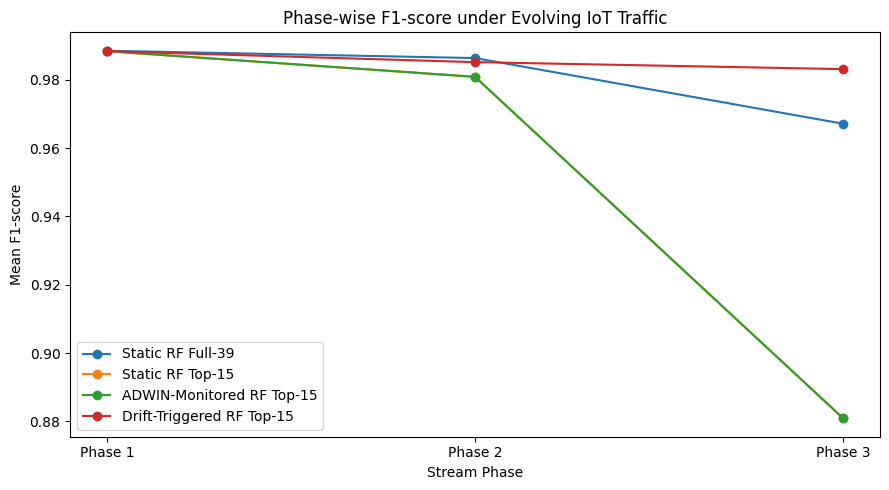

In [43]:
# ============================================================
# 29. Plot phase-wise F1 comparison
# ============================================================

plt.figure(figsize=(9, 5))

for model_name in phasewise_three_seed_summary_df["Model"].unique():
    subset = phasewise_three_seed_summary_df[
        phasewise_three_seed_summary_df["Model"] == model_name
    ]
    plt.plot(
        subset["Phase"],
        subset["F1 Mean"],
        marker="o",
        label=model_name
    )

plt.xlabel("Stream Phase")
plt.ylabel("Mean F1-score")
plt.title("Phase-wise F1-score under Evolving IoT Traffic")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "phasewise_f1_comparison.png",
    dpi=300
)

plt.show()

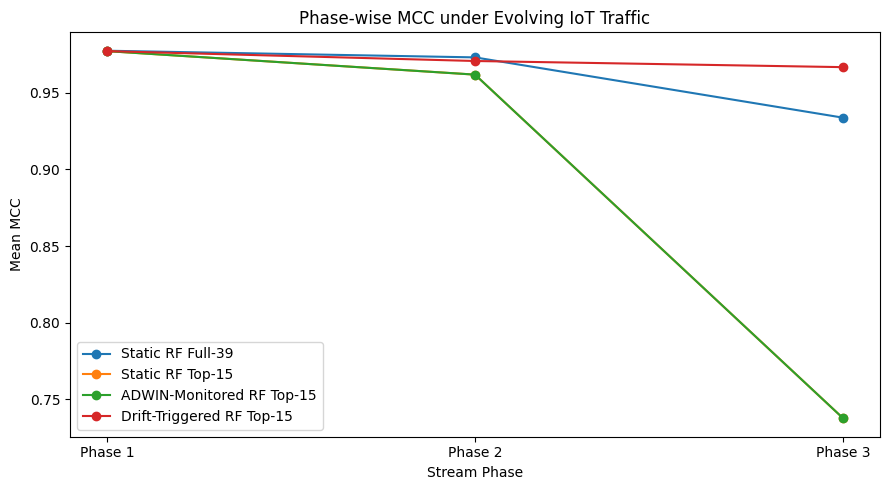

In [44]:
# ============================================================
# 30. Plot phase-wise MCC comparison
# ============================================================

plt.figure(figsize=(9, 5))

for model_name in phasewise_three_seed_summary_df["Model"].unique():
    subset = phasewise_three_seed_summary_df[
        phasewise_three_seed_summary_df["Model"] == model_name
    ]
    plt.plot(
        subset["Phase"],
        subset["MCC Mean"],
        marker="o",
        label=model_name
    )

plt.xlabel("Stream Phase")
plt.ylabel("Mean MCC")
plt.title("Phase-wise MCC under Evolving IoT Traffic")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "phasewise_mcc_comparison.png",
    dpi=300
)

plt.show()